<center>
  <h3>More than a Hack 2027 &middot; Phase 1</h3>
  <h2>Frame-level Ball Possession &mdash; 008 Model Temporal Bentuk Tim</h2>

  <p><strong>Metrica Sports &times; FC Barcelona Innovation Hub &times; Mobile World Capital</strong></p>
</center>

---

### Three Makasih

- **Anggota 1** (<span style="color:gray">email</span>)
- **Anggota 2** (<span style="color:gray">email</span>)
- **Anggota 3** (<span style="color:gray">email</span>)

---

## Ringkasan

Eksperimen 007 menunjukkan bahwa bentuk tim membawa informasi kepemilikan tanpa bola (AUC 0,81 dan 0,87 antar babak), tetapi classifier-nya melihat satu frame pada satu waktu. Kepemilikan berubah pelan dan konsisten: pergerakan tim beberapa detik terakhir lebih informatif daripada satu potret. Eksperimen ini mengganti classifier per frame dengan **jaringan konvolusi temporal (TCN)** yang melihat konteks sekitar 25 detik.

Pelatihan memakai **masking gap bola**: saluran bukti bola disembunyikan pada potongan acak (atau seluruhnya) sehingga model dipaksa memakai bentuk tim ketika bola hilang, yaitu kondisi yang ingin kita atasi. Label tetap pseudo-label dari bola (kendali jelas, |c| > 0,6). Validasi antar babak membandingkan TCN dengan classifier gradient boosting 007 pada titik uji yang sama dan dengan bola sepenuhnya disembunyikan.

Pelatihan berjalan di GPU lokal (RTX 4060), sehingga tidak ada data pertandingan yang meninggalkan mesin dan molab atau Kaggle tidak diperlukan. Tidak ada label tangan dan ground truth tidak dipakai.


# Metodologi

**fitur bentuk tim 007 (cache) → deret waktu 5 fps per babak → TCN dilatasi (konteks sekitar 25 detik) dengan masking bukti bola → pseudo-label bola (|c| > 0,6) → validasi silang antar babak vs gradient boosting 007 → peluang tim per frame (bola disembunyikan) → bukti tambahan bagi Viterbi → λ dikalibrasi ke acuan eksternal 006 → gap bola mati dari 004 → `out/*.csv` → validasi → skor GT publik (hanya pemeriksaan pipeline).**

| asumsi | nilai | alasan |
|---|---|---|
| laju sampel | 5 fps (stride 5) | fitur sudah dihaluskan 2 detik; menghemat 5 kali komputasi |
| konteks | dilatasi 1, 2, 4, 8, 16, 1 dengan kernel 5, sekitar 125 langkah (25 detik) | kepemilikan berubah pelan |
| masking bola | 50% crop bola disembunyikan seluruhnya, 50% potongan acak ±50% | meniru gap bola panjang |
| ensembel | 3 seed, rata-rata peluang | memperkecil variansi pelatihan |
| κ, target kalibrasi | 0,02 dan sekitar 208 ± 21 possession | sama dengan 007 dan 006 |

# Environment

Dijalankan dari dalam repositori, dilatih di GPU lokal. Acuan eksternal diambil dari cache 006; fitur bentuk tim dari cache 007.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").exists())
for p in (ROOT, ROOT / "starter", ROOT / "evaluation", ROOT / "experiments"):
    sys.path.insert(0, str(p))

import subprocess
import warnings
warnings.filterwarnings("ignore")
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

import common
from baseline import smooth, write_submission
from games import GAME, GAMES, anchor_video_frame, half_video_blocks, source_frames

C1, C2, C3, INK, GREY = "#e94f37", "#393e41", "#f6f7eb", "#393e41", "#a3a7a6"
mpl.rcParams.update({
    "figure.facecolor": C3, "savefig.facecolor": C3, "axes.facecolor": "white",
    "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "legend.frameon": False,
    "figure.dpi": 110, "axes.prop_cycle": mpl.cycler(color=[C1, C2, GREY]),
})
def panel(ax, l): ax.text(-0.09, 1.07, l, transform=ax.transAxes, fontsize=12, fontweight="bold", va="top")

FPS = 25; LEN, WID = 105.3, 68.0
N = source_frames("tactical")
BLOCKS3 = half_video_blocks("BAR-ATH")
BL = [(a, b) for _, a, b in BLOCKS3]
GRADED = np.zeros(N, bool); HALF = np.ones(N, int)
for h, a, b in BLOCKS3: GRADED[a:b + 1] = True; HALF[a:b + 1] = h
GRADED_MIN = GRADED.sum() / FPS / 60
OUT = Path(common.HERE) / "008_tcn_shape" / "out"; OUT.mkdir(parents=True, exist_ok=True)
KICKOFF2 = anchor_video_frame(GAMES[GAME]["kickoff_2nd"]) + 1
assert KICKOFF2 == 113742
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print(f"frames: {N} | dinilai: {GRADED.sum()} ({GRADED_MIN:.1f} menit) | perangkat: {DEV}" + (f" ({torch.cuda.get_device_name(0)})" if DEV == 'cuda' else ""))

frames: 199319 | dinilai: 158857 (105.9 menit) | perangkat: cuda (NVIDIA GeForce RTX 4060 Laptop GPU)


# Approach: TCN atas Fitur Bentuk Tim

## [1] Data deret waktu

Fitur bentuk tim 007 dimuat dari cache (14 fitur dari dua sudut pandang), distandarkan, lalu diambil tiap 5 frame di dalam tiap babak. Kanal masukan per langkah: 14 fitur bentuk, 1 kanal validitas, dan 2 kanal bola (skor kendali lunak σ = 3 m dan penanda ada-tidaknya). Sudut pandang kedua (A sebagai *a*) membalik label dan tanda skor kendali, sehingga model simetris.

In [2]:
import sys as _s
ns = {}
src = (ROOT / "experiments" / "007_team_shape" / "007_team_shape.ipynb")
# gunakan cache fitur yang dibuat 007 (arah serang dan fitur bentuk tim); bila belum ada, jalankan 007 dahulu
F = common.cached("team_shape_feats", lambda: (_ for _ in ()).throw(FileNotFoundError("jalankan experiments/007_team_shape dahulu")))
C_S3, OBS_S3 = common.soft_control(3.0)
conf = GRADED & OBS_S3 & (np.abs(C_S3) > 0.6)
y_h = (C_S3 > 0).astype(int)

STRIDE = 5
mu = np.nanmean(F[0][GRADED], 0); sd = np.nanstd(F[0][GRADED], 0) + 1e-6
SEQ = {}
for half, a, b in BLOCKS3:
    ix = np.arange(a, b + 1, STRIDE)
    fe = [(F[v][ix] - mu) / sd for v in (0, 1)]
    valid = [np.isfinite(f).all(1).astype(np.float32) for f in fe]
    SEQ[half] = dict(ix=ix, feat=[np.nan_to_num(f).astype(np.float32) for f in fe], valid=valid,
                     c=C_S3[ix].astype(np.float32), obs=OBS_S3[ix].astype(np.float32),
                     lab=conf[ix], y=y_h[ix].astype(np.float32))
for h, s in SEQ.items():
    print(f"babak {h}: {len(s['ix'])} langkah (5 fps) | berlabel (kendali jelas): {int(s['lab'].sum())}")

babak 1: 15894 langkah (5 fps) | berlabel (kendali jelas): 3369
babak 2: 15878 langkah (5 fps) | berlabel (kendali jelas): 3072


## [2] Model dan pelatihan

TCN dua arah dengan blok residual berdilatasi. Pelatihan memakai potongan acak 256 langkah (sekitar 51 detik). Pada tiap potongan, kanal bola disembunyikan seluruhnya (50%) atau pada potongan acak. Kerugian adalah entropi silang biner pada langkah berlabel.

In [3]:
class TCN(nn.Module):
    def __init__(self, cin=17, ch=64, dil=(1, 2, 4, 8, 16, 1), k=5, p=0.15):
        super().__init__()
        self.inp = nn.Conv1d(cin, ch, 1)
        self.blocks = nn.ModuleList([nn.Sequential(nn.Conv1d(ch, ch, k, padding=d * (k // 2), dilation=d), nn.GELU(), nn.Dropout(p)) for d in dil])
        self.norm = nn.ModuleList([nn.GroupNorm(8, ch) for _ in dil])
        self.head = nn.Conv1d(ch, 1, 1)
    def forward(self, x):                         # x: (B, C, T)
        h = self.inp(x)
        for blk, nm in zip(self.blocks, self.norm): h = h + blk(nm(h))
        return self.head(h).squeeze(1)

def tensors(s, view, mask_ball):
    """(T, 17): 14 fitur + validitas + 2 kanal bola. view 1 membalik tanda skor kendali. mask_ball: bool (T,) bola disembunyikan."""
    sign = 1.0 if view == 0 else -1.0
    c = s["c"] * sign * s["obs"]; ob = s["obs"].copy()
    c = np.where(mask_ball, 0, c); ob = np.where(mask_ball, 0, ob)
    return np.concatenate([s["feat"][view], s["valid"][view][:, None], c[:, None], ob[:, None]], 1).astype(np.float32)

def label(s, view):
    return (s["y"] if view == 0 else 1 - s["y"]).astype(np.float32)

def random_mask(T, rng):
    if rng.random() < 0.5: return np.ones(T, bool)
    m = np.zeros(T, bool); i = 0
    while i < T:
        L = int(rng.integers(8, 80))
        if rng.random() < 0.5: m[i:i + L] = True
        i += L
    return m

def train(halves, seed, steps=1500, bs=48, crop=256):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    net = TCN().to(DEV); opt = torch.optim.AdamW(net.parameters(), lr=2e-3, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=steps)
    for it in range(steps):
        X, Y, Mk = [], [], []
        for _ in range(bs):
            s = SEQ[int(rng.choice(halves))]; T = len(s["ix"]); st = int(rng.integers(0, T - crop)); view = int(rng.integers(0, 2))
            mb = random_mask(crop, rng)
            X.append(tensors({k: (v[st:st + crop] if not isinstance(v, list) else [x[st:st + crop] for x in v]) for k, v in s.items() if k not in ("ix",)}, view, mb))
            Y.append(label({"y": s["y"][st:st + crop]}, view)); Mk.append(s["lab"][st:st + crop].astype(np.float32))
        X = torch.tensor(np.stack(X)).permute(0, 2, 1).to(DEV); Y = torch.tensor(np.stack(Y)).to(DEV); Mk = torch.tensor(np.stack(Mk)).to(DEV)
        loss = (nn.functional.binary_cross_entropy_with_logits(net(X), Y, reduction="none") * Mk).sum() / Mk.sum().clamp(min=1)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return net.eval()

@torch.no_grad()
def predict(net, half, mask_all):
    s = SEQ[half]; T = len(s["ix"]); mb = np.full(T, mask_all)
    out = []
    for v in (0, 1):
        x = torch.tensor(tensors(s, v, mb)).T[None].to(DEV)
        out.append(torch.sigmoid(net(x))[0].cpu().numpy())
    return 0.5 * (out[0] + 1 - out[1])                            # peluang H, rata-rata dua sudut pandang

import time
t0 = time.time(); _ = train([1], 0, steps=50); print(f"50 langkah latih: {time.time() - t0:.1f} dtk (sudah termasuk inisialisasi)")

50 langkah latih: 1.8 dtk (sudah termasuk inisialisasi)


## [3] Validasi silang antar babak: TCN vs gradient boosting 007

Latih pada satu babak, uji pada babak lain, hanya pada langkah berlabel (kendali jelas) dengan **bola disembunyikan seluruhnya**. Gradient boosting 007 dilatih pada langkah berlabel yang sama sebagai pembanding. AUC dihitung terhadap pseudo-label dari bola, bukan ground truth.

In [4]:
def gbdt_probs(train_halves, test_half):
    Xtr, ytr = [], []
    for h in train_halves:
        s = SEQ[h]; m = s["lab"]
        for v in (0, 1):
            raw = F[v][s["ix"]][m]; Xtr.append(raw); ytr.append(s["y"][m] if v == 0 else 1 - s["y"][m])
    g = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08, max_iter=200, random_state=0).fit(np.concatenate(Xtr), np.concatenate(ytr))
    s = SEQ[test_half]
    return 0.5 * (g.predict_proba(F[0][s["ix"]])[:, 1] + 1 - g.predict_proba(F[1][s["ix"]])[:, 1])

rows = []
for tr_h, te_h in ((1, 2), (2, 1)):
    nets = [train([tr_h], seed) for seed in range(3)]
    s = SEQ[te_h]; m = s["lab"]
    p_masked = np.mean([predict(n, te_h, True) for n in nets], 0)
    p_ball = np.mean([predict(n, te_h, False) for n in nets], 0)
    p_gb = gbdt_probs([tr_h], te_h)
    for name, p in (("TCN, bola disembunyikan", p_masked), ("TCN, bola ada", p_ball), ("gradient boosting 007 (bentuk tim)", p_gb)):
        rows.append({"latih": f"babak {tr_h}", "uji": f"babak {te_h}", "model": name, "AUC": roc_auc_score(s["y"][m], p[m]),
                     "akurasi": accuracy_score(s["y"][m], p[m] > 0.5), "n uji": int(m.sum())})
CV = pd.DataFrame(rows); display(CV.round(3))

,latih,uji,model,AUC,akurasi,n uji
0,babak 1,babak 2,"TCN, bola disembunyikan",0.881,0.797,3072
1,babak 1,babak 2,"TCN, bola ada",0.975,0.909,3072
2,babak 1,babak 2,gradient boosting 007 (bentuk tim),0.831,0.752,3072
3,babak 2,babak 1,"TCN, bola disembunyikan",0.894,0.848,3369
4,babak 2,babak 1,"TCN, bola ada",0.986,0.915,3369
5,babak 2,babak 1,gradient boosting 007 (bentuk tim),0.859,0.812,3369


Baca tabel dari tiga sisi: (a) apakah TCN dengan bola disembunyikan mengalahkan gradient boosting pada titik uji yang sama, (b) seberapa jauh bola yang tersedia menaikkan AUC (batas atas), (c) konsistensi di kedua arah babak. Keunggulan yang muncul hanya pada satu arah bukan bukti.

## [4] Model akhir dan peluang tim per frame

Ensembel tiga seed dilatih pada kedua babak. Peluang diprediksi dengan **bola disembunyikan seluruhnya** supaya bukti bentuk tim tidak menggandakan bukti bola pada decoder, lalu diinterpolasi dari 5 fps ke 25 fps.

|p-0,5| pada frame tanpa bola: TCN 0.365 | gradient boosting 0.280
kesepakatan tanda TCN vs gradient boosting (frame tanpa bola): 75.8%


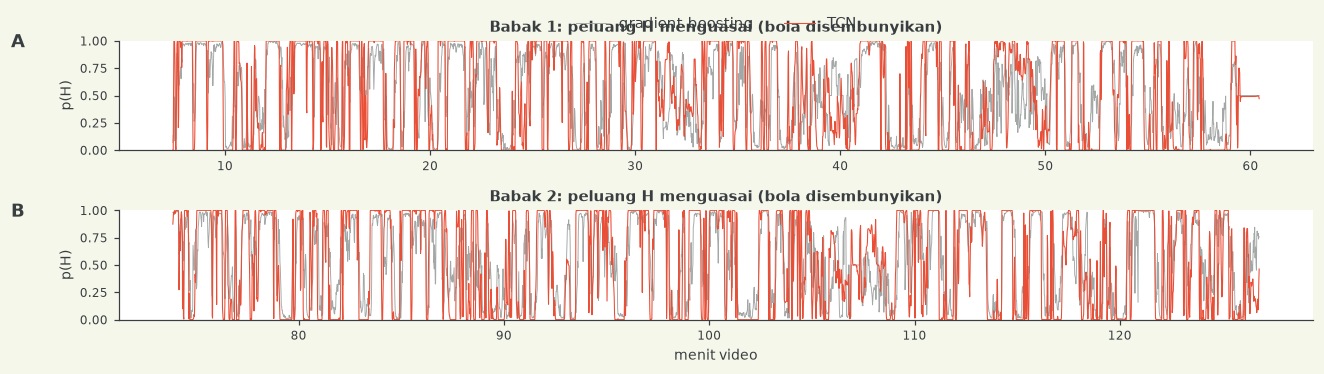

In [5]:
finals = [train([1, 2], seed) for seed in range(3)]
P_TCN = np.full(N, 0.5)
for half, a, b in BLOCKS3:
    p = np.mean([predict(n, half, True) for n in finals], 0)
    ix = SEQ[half]["ix"]
    P_TCN[a:b + 1] = np.interp(np.arange(a, b + 1), ix, p)

np.save(Path(common.CACHE) / "p_tcn.npy", P_TCN)                         # dipakai eksperimen berikutnya (011)
# pembanding: gradient boosting 007 yang dilatih pada seluruh sampel berlabel (stride 5), diinterpolasi
gtr, gy = [], []
for h in (1, 2):
    s = SEQ[h]; m = s["lab"]
    for v in (0, 1):
        gtr.append(F[v][s["ix"]][m]); gy.append(s["y"][m] if v == 0 else 1 - s["y"][m])
GB = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08, max_iter=200, random_state=0).fit(np.concatenate(gtr), np.concatenate(gy))
P_GB = np.full(N, 0.5)
ok = np.isfinite(F[0]).any(1) & np.isfinite(F[1]).any(1)
P_GB[ok] = 0.5 * (GB.predict_proba(F[0][ok])[:, 1] + 1 - GB.predict_proba(F[1][ok])[:, 1])

nb = GRADED & ~OBS_S3
print(f"|p-0,5| pada frame tanpa bola: TCN {np.abs(P_TCN[nb] - .5).mean():.3f} | gradient boosting {np.abs(P_GB[nb] - .5).mean():.3f}")
print(f"kesepakatan tanda TCN vs gradient boosting (frame tanpa bola): {np.mean((P_TCN[nb] > .5) == (P_GB[nb] > .5)):.1%}")

fig, ax = plt.subplots(2, 1, figsize=(12, 3.6), sharex=False)
for a_, (h, s, e) in zip(ax, BLOCKS3):
    t = np.arange(s, e + 1)[::25] / FPS / 60
    a_.plot(t, P_GB[s:e + 1:25], color=GREY, lw=0.6, label="gradient boosting")
    a_.plot(t, P_TCN[s:e + 1:25], color=C1, lw=0.7, label="TCN")
    a_.set(ylim=(0, 1), ylabel="p(H)", title=f"Babak {h}: peluang H menguasai (bola disembunyikan)")
ax[1].set_xlabel("menit video"); ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, 1.35), ncol=2)
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()

## [5] Decoder: bukti bola + bukti TCN

Bukti bola sama dengan 006 dan 007. Bukti tambahan $\kappa \log p_H$ (untuk `H`) dan $\kappa \log (1 - p_H)$ (untuk `A`), κ = 0,02. λ dikalibrasi ulang per varian ke target eksternal.

In [6]:
G = common.gap_dead_ball(); DEAD = G[G.p_dead >= 0.5]
dist = common.team_distances(); dH, dA = dist[:, 0], dist[:, 1]
OBS_N = np.isfinite(dH) & np.isfinite(dA)
E_N = np.zeros(N); E_N[OBS_N] = np.clip((dA[OBS_N] - dH[OBS_N]) / 3.0, -10, 10)
LPB_H, LPB_A = -np.logaddexp(0, -E_N), -np.logaddexp(0, E_N); LPB_H[~OBS_N] = 0; LPB_A[~OBS_N] = 0
def log_p(P):
    pc = np.clip(P, 1e-3, 1 - 1e-3); return np.log(pc), np.log(1 - pc)
LT_H, LT_A = log_p(P_TCN); LG_H, LG_A = log_p(P_GB)

def finish(paths):
    lab = np.full(N, "X", dtype="<U1")
    for (half, a, b), p in zip(BLOCKS3, paths):
        lab[a:b + 1] = np.where(p == 0, "H", "A")
        if half == 2: lab[a:KICKOFF2] = "D"
    for _, r in DEAD.iterrows(): lab[int(r.f0):int(r.f1)] = "D"
    return lab

SPEC = {"ball": (1.0, 0.0, None), "tcn_only": (0.0, 1.0, "tcn"), "ball+tcn_k02": (1.0, 0.02, "tcn"), "ball+gb_k02": (1.0, 0.02, "gb")}
def decode(spec, lam):
    kb, ks, which = SPEC[spec]
    sh, sa = (LT_H, LT_A) if which == "tcn" else (LG_H, LG_A) if which == "gb" else (0, 0)
    h = kb * LPB_H + ks * sh; a = kb * LPB_A + ks * sa
    return finish([common.viterbi_2state(h[x:y + 1], a[x:y + 1], lam) for x, y in BL])

def count(lab):
    n, gaps = 0, []
    for _, a, b in BLOCKS3:
        seg = lab[a:b + 1]; st = []
        for t in ("H", "A"):
            s_, e_ = common.runs(seg == t); st += list(s_)
        st = np.sort(st); n += len(st)
        if len(st) > 1: gaps += list(np.diff(st) / FPS)
    return n, np.array(gaps)

RATE, RATE_SD, _ = common.external_possession_rate()
TARGET, TARGET_SD = RATE * GRADED_MIN, RATE_SD * GRADED_MIN
LAMS = [5, 10, 20, 30, 50, 80, 120, 200, 400]
SWEEP = {k: [(l, count(decode(k, l))[0]) for l in LAMS] for k in SPEC}
def solve(sw, target):
    x = np.log([l for l, _ in sw]); y = np.array([n for _, n in sw], float)
    if target >= y[0]: return float(np.exp(x[0]))
    if target <= y[-1]: return float(np.exp(x[-1]))
    return float(np.exp(np.interp(-target, -y, x)))
CAL = {k: solve(v, TARGET) for k, v in SWEEP.items()}
print(f"target: {TARGET:.0f} +/- {TARGET_SD:.0f} possession")
display(pd.DataFrame({k: [n for _, n in v] for k, v in SWEEP.items()}, index=[f"λ={l}" for l in LAMS]).T)
display(pd.DataFrame({"λ*": CAL}).round(1))

target: 208 +/- 21 possession


,λ=5,λ=10,λ=20,λ=30,λ=50,λ=80,λ=120,λ=200,λ=400
ball,696,477,305,247,191,146,134,108,67
tcn_only,423,399,373,351,322,294,268,220,161
ball+tcn_k02,668,477,306,246,194,147,131,116,78
ball+gb_k02,687,467,304,246,192,147,133,111,68


,λ*
ball,42.8
tcn_only,230.4
ball+tcn_k02,43.6
ball+gb_k02,43.0


## [6] Varian yang dibangun

Setiap varian memakai λ* hasil kalibrasi. Kolom terakhir menunjukkan seberapa sering label pada frame **tanpa bola** berbeda dari varian hanya-bola.

In [7]:
VARS = {"v1_ball": "ball", "v2_tcn_only": "tcn_only", "v3_ball_tcn_k02": "ball+tcn_k02", "v4_ball_gb_k02": "ball+gb_k02"}
for old in OUT.glob("*.csv"): old.unlink()
LAB, rows = {}, []
for name, key in VARS.items():
    lab = decode(key, CAL[key]); LAB[name] = lab; write_submission(str(OUT / f"{name}.csv"), lab)
for name, lab in LAB.items():
    n, g = count(lab)
    live = GRADED & ~OBS_N & (lab != "D") & (LAB["v1_ball"] != "D")
    rows.append({"varian": name, "λ*": round(CAL[VARS[name]], 1), "possession": n, "median awal-ke-awal (dtk)": round(float(np.median(g)), 1),
                 "% D": round(100 * np.mean(lab[GRADED] == "D"), 1), "beda dgn v1 saat bola hilang": f"{np.mean(lab[live] != LAB['v1_ball'][live]):.1%}"})
codes = common.cached("atd_nearest", lambda: None)
base = np.full(N, "X", dtype="<U1"); sm = smooth(codes, 50)
for _, a, b in BLOCKS3: base[a:b + 1] = sm[a:b + 1]
write_submission(str(OUT / "baseline_smooth50.csv"), base)
n, g = count(base)
rows.append({"varian": "baseline_smooth50", "λ*": None, "possession": n, "median awal-ke-awal (dtk)": round(float(np.median(g)), 1),
             "% D": round(100 * np.mean(base[GRADED] == "D"), 1), "beda dgn v1 saat bola hilang": None})
display(pd.DataFrame(rows))

,varian,λ*,possession,median awal-ke-awal (dtk),% D,beda dgn v1 saat bola hilang
0,v1_ball,42.8,212,20.6,22.7,0.0%
1,v2_tcn_only,230.4,208,23.5,22.7,31.7%
2,v3_ball_tcn_k02,43.6,219,19.7,22.7,17.9%
3,v4_ball_gb_k02,43.0,207,21.3,22.7,9.7%
4,baseline_smooth50,NaN,594,5.7,32.3,NaN


## [7] Validasi dan skor (pemeriksaan pipeline)

Skor GT publik hanya memeriksa bahwa berkas benar. Dengan 17 possession, selisih kecil adalah noise dan tidak dipakai untuk memilih varian.

In [8]:
for f in sorted(OUT.glob("*.csv")):
    r = subprocess.run([sys.executable, str(ROOT / "evaluation" / "validate_submission.py"), str(f)], capture_output=True, text=True)
    print(f.name, "->", "VALID" if "Valid." in r.stdout else r.stdout[-200:])
subprocess.run([sys.executable, str(ROOT / "evaluation" / "run_evaluation.py"), "--results", str(OUT), "--out", str(OUT / "reports")], capture_output=True, text=True)
board = pd.read_csv(OUT / "reports" / "scoreboard.csv")
display(board[["rank", "submission", "macro_f1", "spell_f1_mean", "poss", "dur"]].round(4))

baseline_smooth50.csv -> VALID


v1_ball.csv -> VALID


v2_tcn_only.csv -> VALID


v3_ball_tcn_k02.csv -> VALID


v4_ball_gb_k02.csv -> VALID


,rank,submission,macro_f1,spell_f1_mean,poss,dur
0,1,v3_ball_tcn_k02,0.6651,0.5000,11,25.9418
1,2,v1_ball,0.6644,0.5000,11,25.9418
2,3,v2_tcn_only,0.6695,0.4615,9,31.7067
3,4,v4_ball_gb_k02,0.6620,0.4000,9,31.7067
4,5,baseline_smooth50,0.6207,0.3256,26,10.8031


# Ringkasan 008

**Yang dikerjakan.** Classifier per frame 007 diganti TCN dua arah dengan blok residual berdilatasi (konteks sekitar 25 detik pada 5 fps) atas fitur bentuk tim, dilatih dengan masking gap bola (bukti bola disembunyikan seluruhnya pada 50% potongan, dan pada potongan acak pada sisanya) dan pseudo-label bola (kendali jelas). Pelatihan di GPU lokal (RTX 4060, ensembel tiga seed); tidak ada data keluar dari mesin, jadi molab dan Kaggle tidak diperlukan. Semua lima berkas lolos `validate_submission.py`.

**Hasil validasi silang antar babak (terhadap pseudo-label bola, bola disembunyikan seluruhnya).**

| arah | TCN | gradient boosting 007 | TCN dengan bola (batas atas) |
|---|---|---|---|
| latih babak 1, uji babak 2 | AUC 0,881, akurasi 79,7% | 0,831, 75,2% | 0,975 |
| latih babak 2, uji babak 1 | AUC 0,894, akurasi 84,8% | 0,859, 81,2% | 0,986 |

1. **TCN unggul di kedua arah** (AUC +0,05 dan +0,035; akurasi +4,5 dan +3,6 poin) pada titik uji yang sama. Konsistensi dua arah membuat ini lebih meyakinkan daripada hasil satu arah.
2. **Konteks temporal membantu.** Pada frame tanpa bola, TCN lebih tegas (|p − 0,5| = 0,365 vs 0,280) tetapi hanya sepakat dengan gradient boosting pada 75,8% frame, jadi ia memberi informasi baru, bukan sekadar versi lain dari sinyal yang sama.
3. **Keputusan seluruh pertandingan.** Hanya-TCN menghasilkan 208 possession (λ* = 230, median awal-ke-awal 23,5 detik; acuan eksternal 22,3 detik), dan label pada frame tanpa bola berbeda dari hanya-bola pada 31,7% frame. Ball+TCN (κ = 0,02) mengubah 17,9%, ball+gradient boosting 9,7%.

**Pemeriksaan pipeline (GT publik, 17 possession; bukan dasar pemilihan).** `v3_ball_tcn_k02` 0,665 macroF1 dan 0,500 spellF1, sama dengan hanya-bola (0,664 dan 0,500); `v2_tcn_only` 0,670 dan 0,462 (macroF1 tertinggi di papan, tanpa bola untuk tim); `v4_ball_gb_k02` 0,662 dan 0,400; `baseline_smooth50` 0,621 dan 0,326. Selisih ini dalam noise 17 possession, jadi **tidak ada klaim perbaikan atas baseline atau atas hanya-bola pada metrik peringkat**.

**Keterbatasan.**
- **Pergeseran distribusi dan sirkularitas tetap berlaku.** Latih dan uji terjadi pada frame dengan kendali bola jelas; frame yang kita sasar lebih sulit, dan label berasal dari bola sendiri. AUC 0,88 sampai 0,89 kemungkinan optimistis untuk gap sebenarnya.
- **Kenaikan AUC antar model tidak sama dengan kenaikan spellF1.** Kualitas bukti per frame belum teruji terhadap ketepatan batas possession.
- Ensembel hanya tiga seed dan tanpa estimasi variansi untuk gradient boosting.

**Langkah berikutnya.** (a) Uji internal ketepatan batas, misalnya seberapa konsisten titik pergantian antar bukti bola dan TCN di sekitar gap pendek; (b) pseudo-label yang lebih sulit atau tidak bias; (c) bukti video lokal. Dua yang terakhir membutuhkan keputusan Anda, termasuk homografi tactical yang belum diunduh.